# TA-06: Simulasi Sistem Dinamik - Suhu Ruangan ber-AC
Nama: Ari Mauludin | NIM: 301240044 | Kelas: 5C

Model ODE orde-1 (lumped): C dT/dt = (T_out - T)/R + Q_int - Q_max * u

In [3]:
import numpy as np
import matplotlib.pyplot as plt

# ---- Parameter (konstanta) ----
C     = 200_000.0   # kapasitas panas efektif ruangan (J/K)
R     = 0.01        # resistansi termal dinding/ventilasi (K/W)
Q_max = 1000.0      # daya pendinginan maksimum AC (W)

# ---- Input gangguan (disturbance), dianggap konstan ----
T_out = 32.0        # suhu luar ruangan (deg C)
Q_int = 300.0       # beban panas internal: orang + perangkat (W)

# ---- Pengaturan simulasi (metode Euler) ----
dt    = 10.0        # langkah waktu (s)
t_end = 10800.0     # lama simulasi 3 jam (s)
t     = np.arange(0, t_end + dt, dt)

tau = R * C                              # konstanta waktu (s)
T_ss = lambda u: T_out + R * (Q_int - Q_max * u)   # suhu steady state untuk u konstan
print(f"Konstanta waktu tau = R*C = {tau:.0f} s = {tau/60:.1f} menit")
print(f"Steady state AC mati  (u=0): {T_ss(0):.1f} C")
print(f"Steady state AC penuh (u=1): {T_ss(1):.1f} C")

Konstanta waktu tau = R*C = 2000 s = 33.3 menit
Steady state AC mati  (u=0): 35.0 C
Steady state AC penuh (u=1): 25.0 C


In [4]:
def simulasi(u_func, T_awal):
    """Integrasi Euler: T[i] = T[i-1] + dT/dt * dt"""
    T = np.zeros_like(t)
    u = np.array([u_func(ti) for ti in t])
    T[0] = T_awal
    for i in range(1, len(t)):
        dTdt = ((T_out - T[i-1]) / R + Q_int - Q_max * u[i-1]) / C
        T[i] = T[i-1] + dTdt * dt
    return T, u


def plot_respon(T, u, judul, fname, T_ref=None, label_ref=None):
    fig, (a1, a2) = plt.subplots(2, 1, figsize=(7, 5), sharex=True,
                                 gridspec_kw={"height_ratios": [2, 1]})
    a1.plot(t / 60, T, color="blue", label="Suhu ruangan T(t)")
    if T_ref is not None:
        a1.axhline(T_ref, color="orange", linestyle="--", label=label_ref)
    a1.set_ylabel("Suhu T (°C)"); a1.set_title(judul)
    a1.grid(True); a1.legend(loc="best", fontsize=8)
    a2.plot(t / 60, u * 100, color="red", linestyle="--")
    a2.set_ylabel("Kontrol AC u(t) (%)"); a2.set_xlabel("Waktu t (menit)")
    a2.set_ylim(-5, 105); a2.grid(True)
    plt.tight_layout(); plt.savefig(fname, dpi=150); plt.show()

## 1. Simulasi steady state (input konstan)

T akhir (u=0): 34.987 C  | analitik 35.0 C
T akhir (u=1): 25.031 C  | analitik 25.0 C
dT/dt akhir (u=0): 6.72e-06 K/s (mendekati 0)


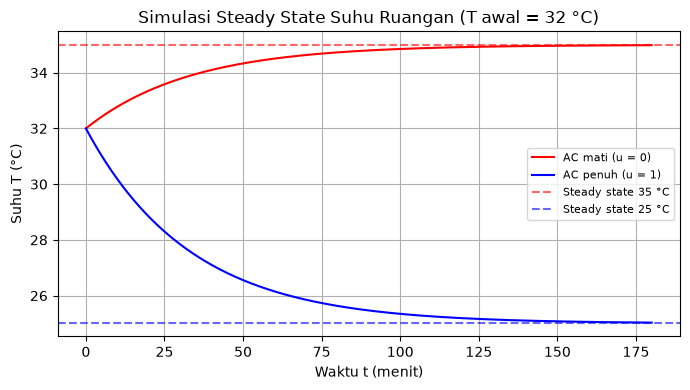

In [5]:
T_mati,  u_mati  = simulasi(lambda ti: 0.0, 32.0)
T_penuh, u_penuh = simulasi(lambda ti: 1.0, 32.0)
print(f"T akhir (u=0): {T_mati[-1]:.3f} C  | analitik {T_ss(0):.1f} C")
print(f"T akhir (u=1): {T_penuh[-1]:.3f} C  | analitik {T_ss(1):.1f} C")
print(f"dT/dt akhir (u=0): {(T_mati[-1]-T_mati[-2])/dt:.2e} K/s (mendekati 0)")

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(t / 60, T_mati,  color="red",  label="AC mati (u = 0)")
ax.plot(t / 60, T_penuh, color="blue", label="AC penuh (u = 1)")
ax.axhline(T_ss(0), color="red",  linestyle="--", alpha=.6, label="Steady state 35 °C")
ax.axhline(T_ss(1), color="blue", linestyle="--", alpha=.6, label="Steady state 25 °C")
ax.set_xlabel("Waktu t (menit)"); ax.set_ylabel("Suhu T (°C)")
ax.set_title("Simulasi Steady State Suhu Ruangan (T awal = 32 °C)")
ax.grid(True); ax.legend(fontsize=8)
plt.tight_layout(); plt.savefig("grafik_1_steady_state.png", dpi=150); plt.show()

## 2. Respon terhadap sinyal kontrol: STEP

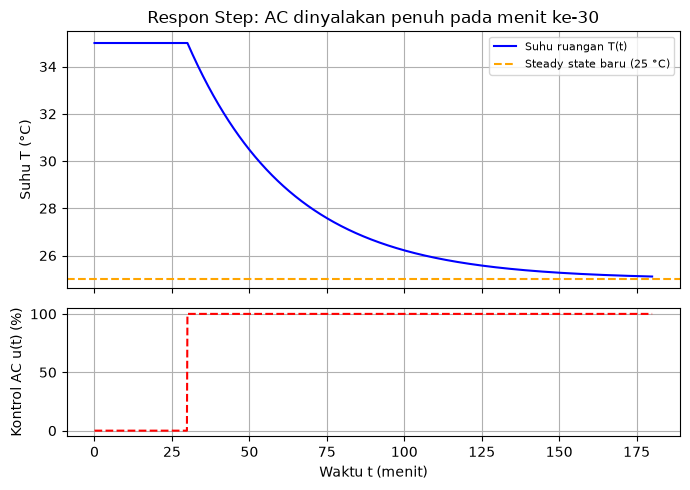

Waktu mencapai 63,2% perubahan: 2000 s setelah step (tau = 2000 s)


In [6]:
T_step, u_step = simulasi(lambda ti: 1.0 if ti >= 1800 else 0.0, T_ss(0))
plot_respon(T_step, u_step, "Respon Step: AC dinyalakan penuh pada menit ke-30",
            "grafik_2_step.png", T_ss(1), "Steady state baru (25 °C)")
i63 = np.argmax(T_step <= T_ss(0) - 0.632 * (T_ss(0) - T_ss(1)))
print(f"Waktu mencapai 63,2% perubahan: {(t[i63]-1800):.0f} s setelah step (tau = {tau:.0f} s)")

## 3. Respon terhadap sinyal RAMP

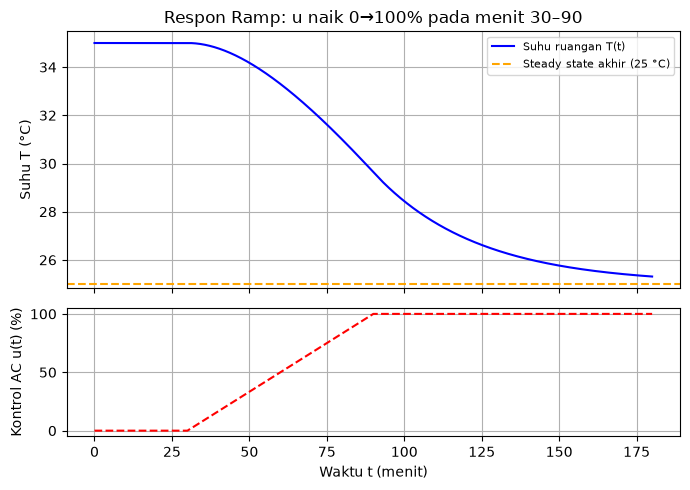

T pada saat ramp selesai (menit 90): 29.64 C | T akhir: 25.31 C


In [7]:
T_ramp, u_ramp = simulasi(lambda ti: float(np.clip((ti - 1800) / 3600, 0, 1)), T_ss(0))
plot_respon(T_ramp, u_ramp, "Respon Ramp: u naik 0→100% pada menit 30–90",
            "grafik_3_ramp.png", T_ss(1), "Steady state akhir (25 °C)")
print(f"T pada saat ramp selesai (menit 90): {T_ramp[int(5400/dt)]:.2f} C | T akhir: {T_ramp[-1]:.2f} C")

## 4. Respon terhadap sinyal IMPULS (pulsa 5 menit)

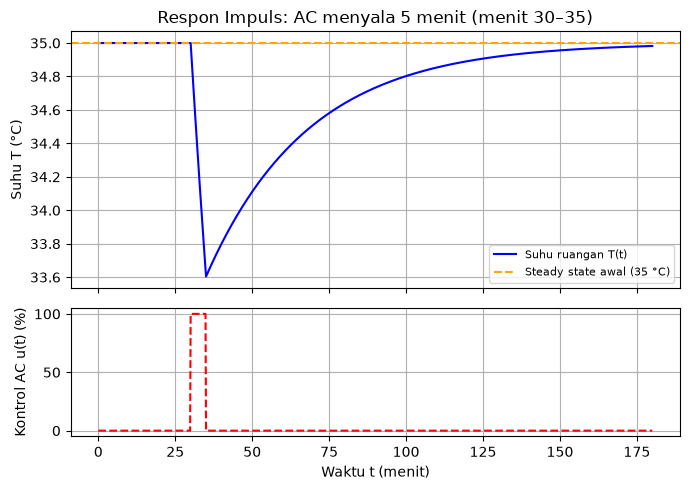

Penurunan suhu terbesar: 1.40 K pada menit 35.0


In [8]:
T_imp, u_imp = simulasi(lambda ti: 1.0 if 1800 <= ti < 2100 else 0.0, T_ss(0))
plot_respon(T_imp, u_imp, "Respon Impuls: AC menyala 5 menit (menit 30–35)",
            "grafik_4_impuls.png", T_ss(0), "Steady state awal (35 °C)")
print(f"Penurunan suhu terbesar: {T_ss(0) - T_imp.min():.2f} K pada menit {t[T_imp.argmin()]/60:.1f}")

## 5. Respon terhadap sinyal SINUSOIDA

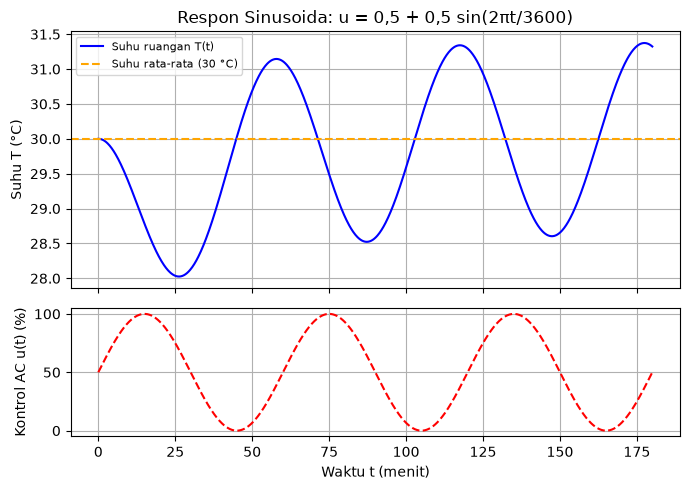

Amplitudo T (simulasi, 2 jam terakhir): 1.38 K | teori 1.38 K
Redaman amplitudo = 0.275 ; fase tertinggal teori = 74.0 derajat


In [9]:
P = 3600.0
u_sin_f = lambda ti: 0.5 + 0.5 * np.sin(2 * np.pi * ti / P)
T_sin, u_sin = simulasi(u_sin_f, T_ss(0.5))
plot_respon(T_sin, u_sin, "Respon Sinusoida: u = 0,5 + 0,5 sin(2πt/3600)",
            "grafik_5_sinus.png", T_ss(0.5), "Suhu rata-rata (30 °C)")
w = 2 * np.pi / P
amp_teori = 0.5 * R * Q_max / np.sqrt(1 + (w * tau) ** 2)
fase_teori = np.degrees(np.arctan(w * tau))
sisa = T_sin[int(7200/dt):]
print(f"Amplitudo T (simulasi, 2 jam terakhir): {(sisa.max()-sisa.min())/2:.2f} K | teori {amp_teori:.2f} K")
print(f"Redaman amplitudo = {amp_teori/(0.5*R*Q_max):.3f} ; fase tertinggal teori = {fase_teori:.1f} derajat")

## 6. Verifikasi perhitungan manual (Euler dt = 300 s, u = 1, T awal = 32 °C)

In [10]:
dt_m, T_m = 300.0, 32.0
print(f"{'t(s)':>6}{'T (Euler)':>12}{'dT/dt':>12}{'T baru':>10}{'T analitik':>13}")
for n in range(6):
    dTdt = ((T_out - T_m) / R + Q_int - Q_max * 1.0) / C
    T_baru = T_m + dTdt * dt_m
    T_an = T_ss(1) + (32.0 - T_ss(1)) * np.exp(-(n * dt_m) / tau)
    print(f"{n*dt_m:>6.0f}{T_m:>12.4f}{dTdt:>12.5f}{T_baru:>10.4f}{T_an:>13.4f}")
    T_m = T_baru
print(f"{6*dt_m:>6.0f}{T_m:>12.4f}{'':>12}{'':>10}{T_ss(1)+(32-T_ss(1))*np.exp(-6*dt_m/tau):>13.4f}")

  t(s)   T (Euler)       dT/dt    T baru   T analitik
     0     32.0000    -0.00350   30.9500      32.0000
   300     30.9500    -0.00298   30.0575      31.0250
   600     30.0575    -0.00253   29.2989      30.1857
   900     29.2989    -0.00215   28.6540      29.4634
  1200     28.6540    -0.00183   28.1059      28.8417
  1500     28.1059    -0.00155   27.6400      28.3066
  1800     27.6400                            27.8460
